# 7000LBSBAI - Programming for Business Analytics
## Week 8 - Code-along: Advanced EDA Techniques
### 📋 ANSWER VERSION: for checking code and independent study

---

**Module:** Programming for Business Analytics  
**Week:** 8  
**Time:** About 60 minutes (four blocks, with your tutor)  
**Topics covered:** Writing functions · Yes/no outcomes and rates · Bands with pd.cut and pd.qcut · Working with dates

---

### How to use this notebook

| Symbol | Meaning |
|--------|---------|
| 👀 Watch | Your tutor explains this cell first -> then you run it |
| 🆘 Solution | The answer to an Adapt task, if you get stuck |
| ✍️ Worked example | Code is already written -> run it and study the output |
| ➡️ Your turn | Write or complete the code in this cell |
| 💬 What does it mean? | Write a short interpretation of your results |
| 🤖 AI activity | A guided activity using Gemini in Colab |
| 🔴 Extension | For students who finish early (optional) |
| 📝 Hint/Tip | Some friendly help and advice |

To run a cell: click on it and press **Shift + Enter**.

---

## ⚠️ BEFORE YOU CONTINUE

### Save a copy of this notebook

Make sure your notebook is saved to your Google Drive:
- **File → Save a copy in Drive**
- Name it: `Week8_CodeAlong_Advanced_EDA_YourName.ipynb`

---

### Turn off AI-powered in-line completions

Go to **Tools** -> **Settings** -> **AI Assistance**

> Uncheck `☐ Show AI-powered inline completions`  

> Check `☑️ Hide generative AI features`

---
## How this code-along works

The same four-block format as Weeks 5 and 6: **👀 Watch → Run → ➡️ Adapt → 💬 Interpret**.

- Each block has a **time limit**. When the time is up, we move on together.
- Stuck on an Adapt task? Open the **🆘 solution**, run it, and go straight to the interpretation.
- Finished early? Try the **🔴 Go further** challenge.

> 📝 **This week the cells do more.** Each Watch cell has several steps. Read the `#` comments: they explain what each part does.

---
## From a basic EDA to a more advanced one

In Week 6 you completed a full, basic EDA. Many business questions are about a **yes/no outcome**: did the customer cancel? Was the delivery late? Did they buy again?

This week you will learn four techniques for questions like these:

| Block | Technique | Why it helps |
|---|---|---|
| 1 | **Functions** | Reuse your code instead of copying it |
| 2 | **Rates** for a yes/no outcome | Compare groups fairly, even when they are different sizes |
| 3 | **Bands** from numbers | Turn a numeric column into groups, to see patterns |
| 4 | **Dates** | Work with days, weeks and lengths of time |

---
## The data: SwiftDeliver, again

The **messy** SwiftDeliver orders from the Week 6 task. You already know the problems, so in Block 1 you will clean them in a new way.

---
## Set up: run this cell

In [ ]:
# ✍️ Set up: just run this cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

url = "https://raw.githubusercontent.com/7000lbsbai/7000LBSBAI/main/datasets/swiftdeliver_orders.csv"
raw = pd.read_csv(url)          # the messy data, exactly as it arrives
print(f"Data loaded: {raw.shape[0]} rows")

Data loaded: 408 rows


> 📝 Note the use of `raw` as the Dataframe name instead of `df`.

---
# Block 1: Writing your own functions
*about 15 minutes*

In Week 6 you cleaned this data one step at a time. If you received **next month's** orders, you would have to write it all again.

A **function** packages steps up under a name, so you can reuse them with one line. You have used many functions already (`print()`, `len()`, `.mean()`); now you will write your own:

```python
def function_name(input):        # def = "define"; the input goes in brackets
    # the steps, indented
    return result                # what the function gives back
```

In [ ]:
# 👀 Block 1: a function that cleans the SwiftDeliver orders
# Watch the demo first, then run this cell yourself

def clean_orders(data):
    """Clean SwiftDeliver orders: the Week 6 cleaning steps in one place."""
    data = data.copy()                                                     # work on a copy, leaving the original untouched
    data = data.drop_duplicates()                                          # 1. remove duplicate rows
    data['restaurant_type'] = data['restaurant_type'].str.strip().str.title()   # 2. tidy the names
    data = data[data['delivery_time_mins'] > 0]                            # 3. remove impossible delivery times
    return data                                                            # give the cleaned table back

# Use the function: one line does all the cleaning
df = clean_orders(raw)

print(f"Rows before cleaning: {raw.shape[0]}")
print(f"Rows after cleaning:  {df.shape[0]}")
print(f"Restaurant types:     {sorted(df['restaurant_type'].unique())}")

Rows before cleaning: 408
Rows after cleaning:  399
Restaurant types:     ['Asian', 'Burger', 'Dessert', 'Healthy', 'Pizza']


> 📝 The text in triple quotes (`"""..."""`) is a **docstring**: a short description of what the function does. Good functions always have one.

### ➡️ Adapt: a function to summarise a column

Write a function called `summarise` that takes **two inputs**, the data and a column name, and prints the **mean, median, minimum and maximum** of that column with f-strings. Then use it for `delivery_time_mins` **and** `order_value`.

> 📝 **Hint:** start with `def summarise(data, column):`. Inside, use `data[column]` instead of a column name, so the same code works for any column.

In [ ]:
# ➡️ Adapt: a function to summarise a column
def summarise(data, column):
    """Print the mean, median, minimum and maximum of one column."""
    print(f"Summary of {column}")
    print(f"  Mean:    {data[column].mean():.2f}")
    print(f"  Median:  {data[column].median():.2f}")
    print(f"  Minimum: {data[column].min():.2f}")
    print(f"  Maximum: {data[column].max():.2f}")

summarise(df, 'delivery_time_mins')
summarise(df, 'order_value')

# Delivery time: mean 26.18, median 24.00, min 10.00, max 63.00

Summary of delivery_time_mins
  Mean:    26.18
  Median:  24.00
  Minimum: 10.00
  Maximum: 63.00
Summary of order_value
  Mean:    27.55
  Median:  26.06
  Minimum: 6.00
  Maximum: 84.26


<details>
<summary><b>🆘 Stuck? Click here for the solution to "a function to summarise a column"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
def summarise(data, column):
    """Print the mean, median, minimum and maximum of one column."""
    print(f"Summary of {column}")
    print(f"  Mean:    {data[column].mean():.2f}")
    print(f"  Median:  {data[column].median():.2f}")
    print(f"  Minimum: {data[column].min():.2f}")
    print(f"  Maximum: {data[column].max():.2f}")

summarise(df, 'delivery_time_mins')
summarise(df, 'order_value')
```
</details>

### 💬 What does it mean?

- Why is it useful to put the cleaning steps into a function?
- When might you use `clean_orders()` or `summarise()` again?

**✏️ MODEL ANSWER:**

A function means the cleaning is written **once** and can be **reused** with a single line, so there is less copying and fewer chances to make a mistake. If the steps need to change, you change them in one place. `clean_orders()` could clean **next month's** SwiftDeliver orders in one line, as long as they have the same problems, and `summarise()` works for **any** numeric column in any dataset. In Assessment 2, functions like these can make your notebook shorter and easier to follow.

### 🔴 Go further: report what the function changed

Improve `clean_orders()` so that it also **prints how many rows it removed**. Hint: save the number of rows at the start with `start = len(data)`.

In [ ]:
# 🔴 Go further: report what the function changed
def clean_orders(data):
    """Clean SwiftDeliver orders, and report how many rows were removed."""
    data = data.copy()
    start = len(data)
    data = data.drop_duplicates()
    data['restaurant_type'] = data['restaurant_type'].str.strip().str.title()
    data = data[data['delivery_time_mins'] > 0]
    print(f"Removed {start - len(data)} rows ({start} to {len(data)})")
    return data

df = clean_orders(raw)

# Removed 9 rows (408 to 399)

Removed 9 rows (408 to 399)


---
# Block 2: A yes/no outcome, and rates
*about 15 minutes*

SwiftDeliver promises delivery within **30 minutes**. Was each order **late**?

- `np.where()` (Week 4) creates a **1/0 column**: 1 for late, 0 for on time.
- The **mean of a 1/0 column is a rate**: if 3 orders out of 10 are late, the mean is 0.3, or 30%.
- Rates let you compare groups **fairly**, even when they are different sizes.

`sns.barplot()` draws the **mean of each group**. The black lines are **error bars**, showing the 95% confidence interval: the same idea as the shaded band around a trend line in Week 6.

Overall late rate: 26.8%

weather
Dry     18.9
Rain    45.4
Name: late, dtype: float64


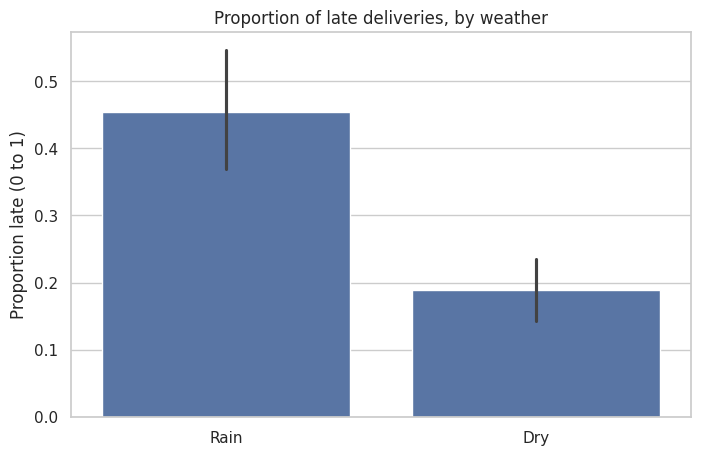

In [ ]:
# 👀 Block 2: the late rate overall and by weather
# Watch the demo first, then run this cell yourself

# 1. Create a 1/0 column: 1 if the delivery was late, 0 if it was on time
df['late'] = np.where(df['delivery_time_mins'] > 30, 1, 0)

# 2. The mean of a 1/0 column is a rate
print(f"Overall late rate: {df['late'].mean() * 100:.1f}%")
print()

# 3. The late rate in each group
late_by_weather = (df.groupby('weather')['late'].mean() * 100).round(1)
print(late_by_weather)

# 4. A bar chart of the rates, with 95% confidence intervals
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='weather', y='late')
plt.title('Proportion of late deliveries, by weather')
plt.xlabel('')
plt.ylabel('Proportion late (0 to 1)')
plt.show()

> 📝 `pd.crosstab()` shows the same thing as a table. `normalize='index'` turns each row into proportions:
>
> `pd.crosstab(df['weather'], df['late'], normalize='index')`
>
> Try it below and examine the output:

In [ ]:
# ✍️ pd.crosstab(): just run this cell
pd.crosstab(df['weather'], df['late'], normalize='index')

late,0,1
weather,,
Dry,0.810714,0.189286
Rain,0.546218,0.453782


### ➡️ Adapt: late rate by restaurant type

Calculate the late rate (%) for each **restaurant type**, sorted from highest to lowest, then draw a bar chart of the rates with a title and axis labels.

> 📝 **Hint:** change `'weather'` to `'restaurant_type'`. To sort the bars, save the sorted rates and use `order=late_by_type.index` in the chart.

restaurant_type
Healthy    28.9
Pizza      28.6
Dessert    27.8
Asian      26.0
Burger     24.5
Name: late, dtype: float64


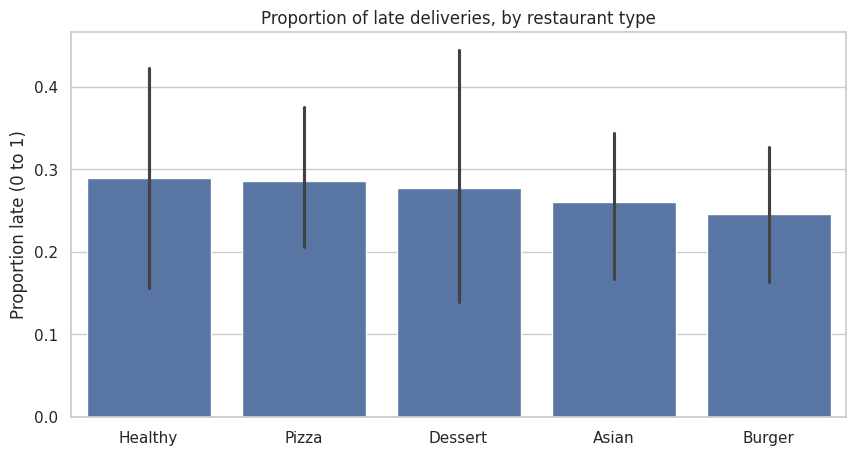

In [ ]:
# ➡️ Adapt: late rate by restaurant type
late_by_type = (df.groupby('restaurant_type')['late'].mean() * 100).round(1).sort_values(ascending=False)
print(late_by_type)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='restaurant_type', y='late', order=late_by_type.index)
plt.title('Proportion of late deliveries, by restaurant type')
plt.xlabel('')
plt.ylabel('Proportion late (0 to 1)')
plt.show()

# All between 24.5% and 28.9%, with overlapping error bars

<details>
<summary><b>🆘 Stuck? Click here for the solution to "late rate by restaurant type"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
late_by_type = (df.groupby('restaurant_type')['late'].mean() * 100).round(1).sort_values(ascending=False)
print(late_by_type)
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='restaurant_type', y='late', order=late_by_type.index)
plt.title('Proportion of late deliveries, by restaurant type')
plt.xlabel('')
plt.ylabel('Proportion late (0 to 1)')
plt.show()
```
</details>

### 💬 What does it mean?

- How much does the weather change the chance of a late delivery?
- Does the type of restaurant matter? What do the error bars tell you?

**✏️ MODEL ANSWER:**

Overall, **26.8%** of deliveries are late. Rain more than **doubles** the late rate: **45.4%** of rainy-day deliveries are late, against **18.9%** in dry weather, and the error bars do not overlap, so this is a clear difference. Restaurant type makes very little difference (from **24.5%** for Burger to **28.9%** for Healthy), and the error bars **overlap a lot**, so these small differences could easily be due to chance. SwiftDeliver should focus on **weather**, not restaurant type, to reduce late deliveries.

### 🔴 Go further: a crosstab with totals

Create a crosstab of `weather` and `late` with `normalize='index'` and `margins=True`, which adds an **All** row. Multiply by 100 and round to 1 decimal place.

In [ ]:
# 🔴 Go further: a crosstab with totals
(pd.crosstab(df['weather'], df['late'], normalize='index', margins=True) * 100).round(1)

# The 1 column gives the late rate: Dry 18.9, Rain 45.4, All 26.8

late,0,1
weather,,
Dry,81.1,18.9
Rain,54.6,45.4
All,73.2,26.8


---
# Block 3: Bands: turning numbers into groups
*about 15 minutes*

Is a long delivery **more likely** to be late? A scatter plot of a 1/0 column is hard to read, so instead we put the distances into **bands** and calculate the late rate in each band.

- `pd.cut()` makes bands with **edges you choose**, e.g. 0 to 2 km, 2 to 4 km.
- `pd.qcut()` makes bands with **equal numbers of rows** in each (e.g. four quarters).

> 📝 `observed=True` in `groupby` tells pandas to use only the bands that appear in the data. It also stops a warning message.

distance_band
0-2 km    137
2-4 km    155
4-6 km     64
6+ km      43
Name: count, dtype: int64

distance_band
0-2 km     1.5
2-4 km    14.8
4-6 km    64.1
6+ km     95.3
Name: late, dtype: float64


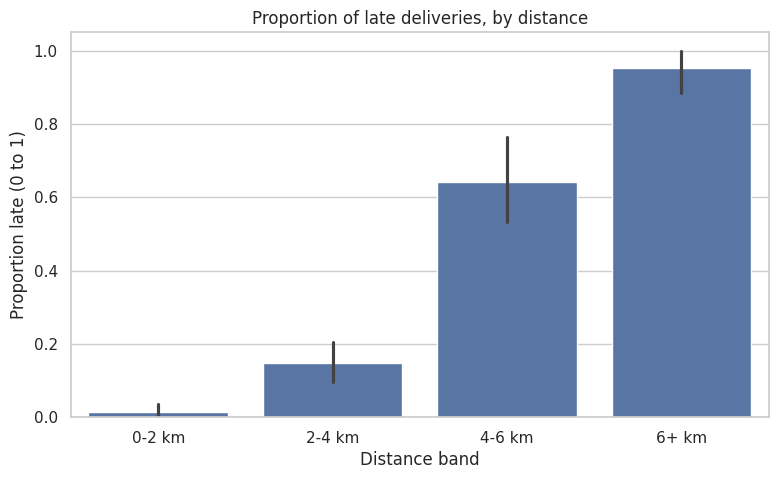

In [ ]:
# 👀 Block 3: distance bands, and the late rate in each
# Watch the demo first, then run this cell yourself

# 1. Choose the band edges and labels (one fewer label than edges)
edges = [0, 2, 4, 6, 13]
labels = ['0-2 km', '2-4 km', '4-6 km', '6+ km']
df['distance_band'] = pd.cut(df['distance_km'], bins=edges, labels=labels)

# 2. How many orders are in each band?
print(df['distance_band'].value_counts().sort_index())
print()

# 3. The late rate in each band
print((df.groupby('distance_band', observed=True)['late'].mean() * 100).round(1))

# 4. Chart it
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='distance_band', y='late')
plt.title('Proportion of late deliveries, by distance')
plt.xlabel('Distance band')
plt.ylabel('Proportion late (0 to 1)')
plt.show()

### ➡️ Adapt: rating by delivery time band

Create **delivery time bands**: under 20, 20-30, 30-40 and 40+ minutes (edges `[0, 20, 30, 40, 70]`). Then calculate the **average rating** in each band, and draw a bar chart.

> 📝 **Hint:** use the Watch cell, with `'delivery_time_mins'` as the column to cut and `'rating'` instead of `'late'`. Missing ratings are skipped automatically.

time_band
Under 20    4.29
20-30       3.86
30-40       3.31
40+         2.27
Name: rating, dtype: float64


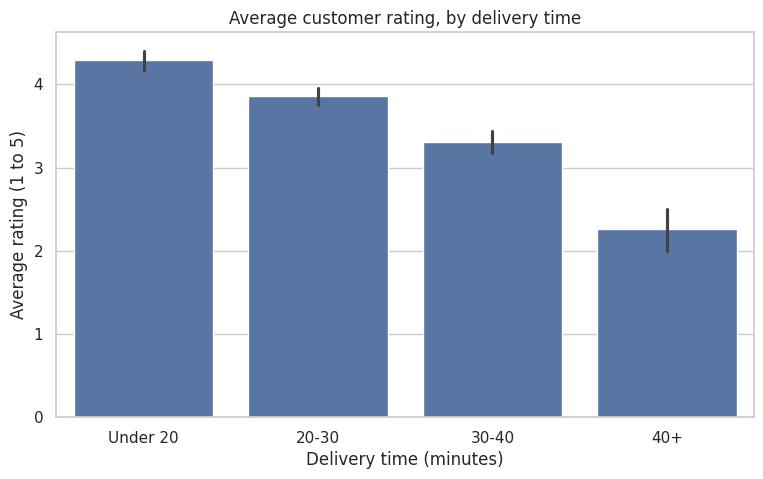

In [ ]:
# ➡️ Adapt: rating by delivery time band
edges = [0, 20, 30, 40, 70]
labels = ['Under 20', '20-30', '30-40', '40+']
df['time_band'] = pd.cut(df['delivery_time_mins'], bins=edges, labels=labels)

print(df.groupby('time_band', observed=True)['rating'].mean().round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='time_band', y='rating')
plt.title('Average customer rating, by delivery time')
plt.xlabel('Delivery time (minutes)')
plt.ylabel('Average rating (1 to 5)')
plt.show()

# 4.29, 3.86, 3.31, 2.27: a steady fall

<details>
<summary><b>🆘 Stuck? Click here for the solution to "rating by delivery time band"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
edges = [0, 20, 30, 40, 70]
labels = ['Under 20', '20-30', '30-40', '40+']
df['time_band'] = pd.cut(df['delivery_time_mins'], bins=edges, labels=labels)
print(df.groupby('time_band', observed=True)['rating'].mean().round(2))
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='time_band', y='rating')
plt.title('Average customer rating, by delivery time')
plt.xlabel('Delivery time (minutes)')
plt.ylabel('Average rating (1 to 5)')
plt.show()
```
</details>

### 💬 What does it mean?

- How does the late rate change with distance? Where is the biggest jump?
- How does the average rating change as deliveries take longer?
- Why might bands be easier to explain to a manager than a correlation coefficient?

**✏️ MODEL ANSWER:**

The late rate rises steeply with distance: only **1.5%** of deliveries under 2 km are late, rising to **64.1%** for 4-6 km and **95.3%** for over 6 km. The biggest jump is between **2-4 km and 4-6 km**, which suggests a practical limit of about 4 km for the 30-minute promise. Ratings fall steadily as deliveries take longer, from **4.29** for under 20 minutes to **2.27** for over 40. Bands are easier to explain than *r* because they give **concrete, actionable** statements ("almost every delivery over 6 km is late") instead of a single abstract number.

### 🔴 Go further: equal-sized bands with pd.qcut

Use `pd.qcut(df['distance_km'], 4, labels=[...])` to split distance into **four equal-sized groups**. Print the number of orders and the late rate in each. How is this different from `pd.cut()`?

In [ ]:
# 🔴 Go further: equal-sized bands with pd.qcut
df['distance_quarter'] = pd.qcut(df['distance_km'], 4, labels=['Shortest 25%', 'Second', 'Third', 'Longest 25%'])

print(df['distance_quarter'].value_counts().sort_index())
print((df.groupby('distance_quarter', observed=True)['late'].mean() * 100).round(1))

# About 100 orders in each group (not exactly, because some distances are tied).
# Late rate: 1.0%, 6.6%, 24.0%, 80.6%. qcut chooses the edges for you; cut uses yours.

distance_quarter
Shortest 25%    100
Second          106
Third           100
Longest 25%      93
Name: count, dtype: int64
distance_quarter
Shortest 25%     1.0
Second           6.6
Third           24.0
Longest 25%     80.6
Name: late, dtype: float64


---
# Block 4: Working with dates
*about 15 minutes*

Dates are loaded as **text**, so pandas cannot work with them yet. `pd.to_datetime()` converts them into real dates, and then the `.dt` accessor gives you parts of each date:

| Code | Gives you |
|---|---|
| `.dt.day_name()` | Monday, Tuesday… |
| `.dt.month` | 1 to 12 |
| `.dt.year` | e.g. 2024 |

You can also **subtract** dates to find the time between them.

Orders from 2024-09-02 to 2024-09-29
That is 27 days

day_name
Monday       26.8
Tuesday      28.6
Wednesday    24.6
Thursday     22.4
Friday       35.0
Saturday     29.0
Sunday       19.2
Name: late, dtype: float64


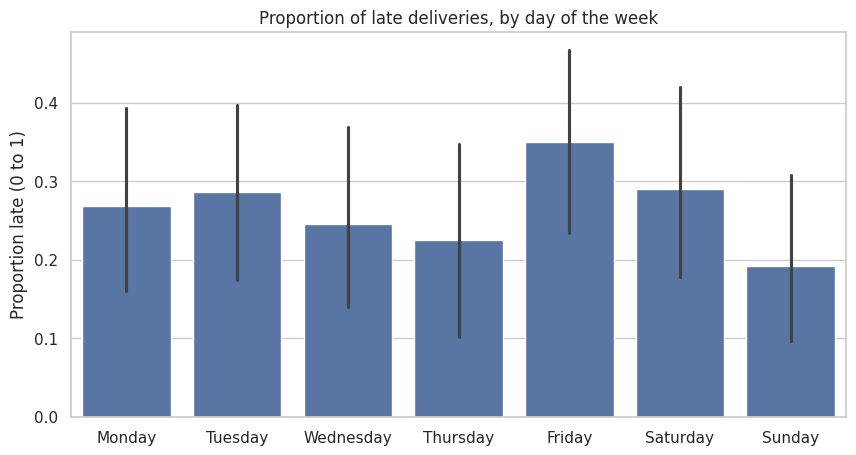

In [ ]:
# 👀 Block 4: converting dates, and the late rate by day of the week
# Watch the demo first, then run this cell yourself

# 1. Convert the text into real dates
df['order_date'] = pd.to_datetime(df['order_date'])
print(f"Orders from {df['order_date'].min().date()} to {df['order_date'].max().date()}")
print(f"That is {(df['order_date'].max() - df['order_date'].min()).days} days")
print()

# 2. Get the day of the week from each date
df['day_name'] = df['order_date'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# 3. The late rate for each day, in order Monday to Sunday
late_by_day = (df.groupby('day_name')['late'].mean() * 100).reindex(day_order).round(1)
print(late_by_day)

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='day_name', y='late', order=day_order)
plt.title('Proportion of late deliveries, by day of the week')
plt.xlabel('')
plt.ylabel('Proportion late (0 to 1)')
plt.show()

> 📝 `.reindex(day_order)` puts the results in the order you choose. Without it, pandas sorts the days alphabetically (Friday, Monday, Saturday…).

### ➡️ Adapt: delivery time by day of the week

Calculate the **average delivery time** for each day of the week, in order Monday to Sunday, rounded to 1 decimal place.

> 📝 **Hint:** the same pattern as step 3 of the Watch cell, with `'delivery_time_mins'` instead of `'late'` (no need for `* 100`).

In [ ]:
# ➡️ Adapt: delivery time by day of the week
(df.groupby('day_name')['delivery_time_mins'].mean()).reindex(day_order).round(1)

# Between 24.7 (Wednesday) and 27.0 minutes (Tuesday, Friday): almost the same every day

,delivery_time_mins
day_name,
Monday,25.8
Tuesday,27.0
Wednesday,24.7
Thursday,26.6
Friday,27.0
Saturday,25.8
Sunday,26.2


<details>
<summary><b>🆘 Stuck? Click here for the solution to "delivery time by day of the week"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
(df.groupby('day_name')['delivery_time_mins'].mean()).reindex(day_order).round(1)
```
</details>

### 💬 What does it mean?

- The late rate varies from 19.2% (Sunday) to 35.0% (Friday). Does that mean Fridays are a real problem?
- What do the average delivery times and the error bars suggest?

**✏️ MODEL ANSWER:**

Probably **not**. The average delivery time is almost the **same every day** (between 24.7 and 27.0 minutes), and the error bars on the chart **overlap a lot**. Each day only has around **57 orders** (four weeks of data), so a few late deliveries can move the rate a lot: this is the Week 4 lesson that **small groups give unreliable statistics**. Before acting on the Friday figure, SwiftDeliver would need more weeks of data. Not every difference in a chart is a real pattern.

### 🔴 Go further: time since the first order

Subtracting dates gives a **time difference**. Create a column `days_since_start`: the number of days between each order and the **first** order in the data. Hint: `(df['order_date'] - df['order_date'].min()).dt.days`

In [ ]:
# 🔴 Go further: time since the first order
df['days_since_start'] = (df['order_date'] - df['order_date'].min()).dt.days
print(df['days_since_start'].describe().round(1))

# From 0 to 27 days. In the task you use the same idea to work out how long each member has belonged to a gym

count    399.0
mean      13.3
std        8.2
min        0.0
25%        6.0
50%       13.0
75%       20.0
max       27.0
Name: days_since_start, dtype: float64


---
## ✅ End of Code-along: Recap

You have learned four techniques for a more advanced EDA:

| Technique | Code |
|---|---|
| Write a function | `def name(data):` … `return data` |
| Create a 1/0 outcome | `df['late'] = np.where(condition, 1, 0)` |
| A rate for each group | `df.groupby('group')['late'].mean() * 100` |
| A table of rates | `pd.crosstab(df['a'], df['b'], normalize='index')` |
| Bands you choose | `pd.cut(df['col'], bins=edges, labels=labels)` |
| Equal-sized bands | `pd.qcut(df['col'], 4)` |
| Convert dates | `pd.to_datetime(df['col'])` · `.dt.day_name()` · `.dt.year` |

---

### 💾 Before you leave

Make sure your notebook is saved to your Google Drive, if you have not done so already:
- **File → Save a copy in Drive**
- Name it: `Week8_CodeAlong_Advanced_EDA_YourName.ipynb`

---

### 🔮 Next: the Week 8 task

After the break, you will use these techniques on a new dataset, **FitLife Gyms**, to find out what is linked to members cancelling. You will also use **Gemini** for the first time, to help you understand code.